100%|██████████| 26.4M/26.4M [00:01<00:00, 19.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 306kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.67MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.98MB/s]


Memulai Training Autoencoder...
Epoch [1/5], Loss Rekonstruksi: 0.0422
Epoch [2/5], Loss Rekonstruksi: 0.0234
Epoch [3/5], Loss Rekonstruksi: 0.0206
Epoch [4/5], Loss Rekonstruksi: 0.0192
Epoch [5/5], Loss Rekonstruksi: 0.0183


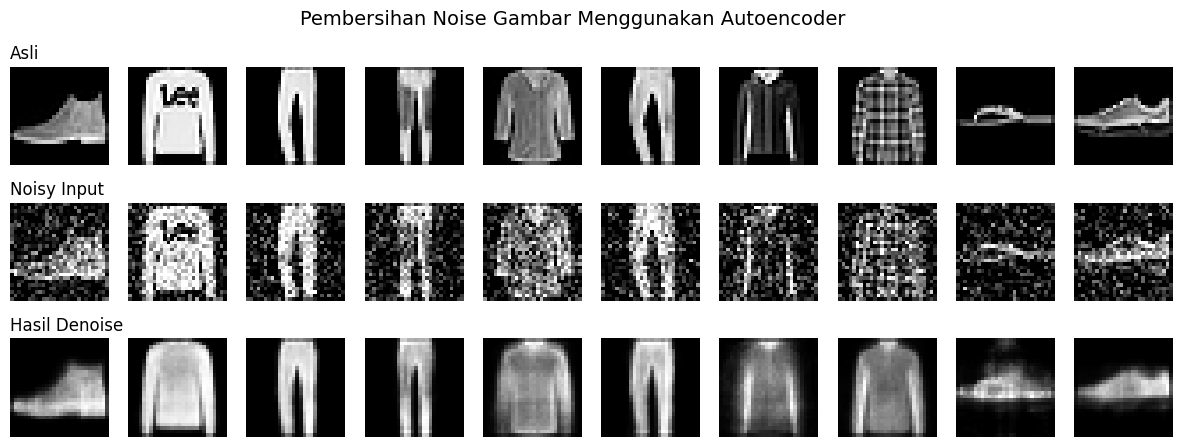

In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# 1. LOAD DATASET (Fashion MNIST)
transform = transforms.Compose([transforms.ToTensor()])

train_dataset = datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(dataset=train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=10, shuffle=False)


# 2. ARSITEKTUR AUTOENCODER (PYTORCH)
class Autoencoder(nn.Module):

    def __init__(self):
        super(Autoencoder, self).__init__()
        # Encoder: 784 -> 128 -> 32
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
        )
        # Decoder: 32 -> 128 -> 784
        self.decoder = nn.Sequential(
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 28 * 28),
            nn.Sigmoid(),  # Output piksel [0, 1]
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)  # Flatten 28x28 -> 784
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)
        return reconstructed.view(-1, 1, 28, 28)


# 3. TRAINING MODEL (DENOISING AUTOENCODER)
model = Autoencoder()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

noise_factor = 0.25  # Intensitas noise
epochs = 5

print("Memulai Training Autoencoder...")
for epoch in range(epochs):
    running_loss = 0.0
    for data, _ in train_loader:
        # Tambahkan noise buatan ke input
        noisy_data = data + noise_factor * torch.randn_like(data)
        noisy_data = torch.clamp(noisy_data, 0.0, 1.0)

        optimizer.zero_grad()
        outputs = model(noisy_data)
        loss = criterion(
            outputs, data
        )  # Target loss adalah gambar bersih (asli)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch [{epoch+1}/{epochs}], Loss Rekonstruksi: {running_loss/len(train_loader):.4f}"
    )


# 4. EVALUASI & VISUALISASI HASIL DENOISING
model.eval()
with torch.no_grad():
    for test_images, _ in test_loader:
        noisy_test = test_images + noise_factor * torch.randn_like(test_images)
        noisy_test = torch.clamp(noisy_test, 0.0, 1.0)
        reconstructed_test = model(noisy_test)
        break

# Plot 3 Baris: Gambar Asli, Gambar Ber-Noise, Hasil Denoising Autoencoder
fig, axes = plt.subplots(3, 10, figsize=(15, 5))
for i in range(10):
    # Baris 1: Gambar Asli
    axes[0, i].imshow(test_images[i].squeeze(), cmap="gray")
    axes[0, i].axis("off")
    if i == 0:
        axes[0, i].set_title("Asli", loc="left")

    # Baris 2: Input Ber-noise
    axes[1, i].imshow(noisy_test[i].squeeze(), cmap="gray")
    axes[1, i].axis("off")
    if i == 0:
        axes[1, i].set_title("Noisy Input", loc="left")

    # Baris 3: Rekonstruksi Autoencoder
    axes[2, i].imshow(reconstructed_test[i].squeeze(), cmap="gray")
    axes[2, i].axis("off")
    if i == 0:
        axes[2, i].set_title("Hasil Denoise", loc="left")

plt.suptitle("Pembersihan Noise Gambar Menggunakan Autoencoder", fontsize=14)
plt.show()